
# Customer Churn & Retention Analysis

## Objective
Analyse customer churn patterns, identify customer characteristics associated with churn, and develop data-driven customer retention recommendations using Python.

## Tools
Python, Pandas, NumPy, Matplotlib, Seaborn, SciPy, and Statsmodels.


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:

print("Dataset shape:", df.shape)

display(df.head())


df.info()


Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [4]:

display(df.describe(include="all").T)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,3186-AJIEK,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:


missing_values = df.isnull().sum()

print("Missing values by column:")
print(missing_values[missing_values > 0])

print("\nTotal missing values:", df.isnull().sum().sum())


Missing values by column:
Series([], dtype: int64)

Total missing values: 0


In [6]:

print("Duplicate rows:", df.duplicated().sum())

print("Duplicate customer IDs:", df["customerID"].duplicated().sum())

print("Unique customers:", df["customerID"].nunique())


Duplicate rows: 0
Duplicate customer IDs: 0
Unique customers: 7043


In [7]:

print("TotalCharges data type:", df["TotalCharges"].dtype)

blank_charges = (
    df["TotalCharges"]
    .astype(str)
    .str.strip()
    .eq("")
    .sum()
)

print("Blank TotalCharges values:", blank_charges)

# Display any rows with blank TotalCharges
display(df[df["TotalCharges"].astype(str).str.strip().eq("")])


TotalCharges data type: object
Blank TotalCharges values: 11


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,No,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,Yes,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,Yes,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,Yes,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,,No


In [8]:

df["TotalCharges"] = df["TotalCharges"].replace(r"^\s*$", np.nan, regex=True)

df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

print("Data type:", df["TotalCharges"].dtype)
print("Missing values:", df["TotalCharges"].isna().sum())

Data type: float64
Missing values: 11


In [9]:

df.loc[
    df["TotalCharges"].isna(),
    ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]
]

,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,NaN
753,3115-CZMZD,0,20.25,NaN
936,5709-LVOEQ,0,80.85,NaN
1082,4367-NUYAO,0,25.75,NaN
1340,1371-DWPAZ,0,56.05,NaN
3331,7644-OMVMY,0,19.85,NaN
3826,3213-VVOLG,0,25.35,NaN
4380,2520-SGTTA,0,20.00,NaN
5218,2923-ARZLG,0,19.70,NaN
6670,4075-WKNIU,0,73.35,NaN


In [10]:
df.loc[
    df["TotalCharges"].isna() & (df["tenure"] == 0),
    "TotalCharges"
] = 0

In [11]:
df.loc[
    df["TotalCharges"].isna() & (df["tenure"] == 0),
    "TotalCharges"
] = 0

In [12]:
print("Data type:", df["TotalCharges"].dtype)
print("Missing values:", df["TotalCharges"].isna().sum())
print(df["TotalCharges"].describe())

Data type: float64
Missing values: 0
count    7043.000000
mean     2279.734304
std      2266.794470
min         0.000000
25%       398.550000
50%      1394.550000
75%      3786.600000
max      8684.800000
Name: TotalCharges, dtype: float64


In [13]:

df["TotalCharges"] = df["TotalCharges"].replace(r"^\s*$", np.nan, regex=True)


df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

print("Data type:", df["TotalCharges"].dtype)
print("Missing values:", df["TotalCharges"].isna().sum())

Data type: float64
Missing values: 0


In [14]:

df.loc[
    df["TotalCharges"].isna(),
    ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]
]

,customerID,tenure,MonthlyCharges,TotalCharges


In [16]:
df.loc[
    df["TotalCharges"].isna() & (df["tenure"] == 0),
    "TotalCharges"
] = 0

In [17]:
print("Data type:", df["TotalCharges"].dtype)
print("Missing values:", df["TotalCharges"].isna().sum())
print(df["TotalCharges"].describe())

Data type: float64
Missing values: 0
count    7043.000000
mean     2279.734304
std      2266.794470
min         0.000000
25%       398.550000
50%      1394.550000
75%      3786.600000
max      8684.800000
Name: TotalCharges, dtype: float64


In [18]:

churn_charges = (
    df.groupby("Churn")["TotalCharges"]
    .agg(["count", "mean", "median"])
    .round(2)
)

print(churn_charges)

       count     mean   median
Churn                         
No      5174  2549.91  1679.52
Yes     1869  1531.80   703.55


In [20]:

tenure_analysis = (
    df.groupby("Churn")["tenure"]
    .agg(["count", "mean", "median"])
    .round(2)
)

print(tenure_analysis)

       count   mean  median
Churn                      
No      5174  37.57    38.0
Yes     1869  17.98    10.0


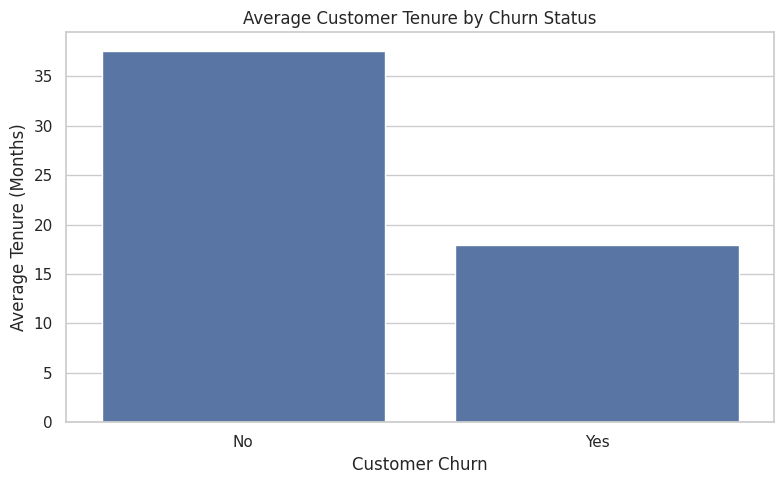

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

tenure_mean = df.groupby("Churn", as_index=False)["tenure"].mean()


plt.figure(figsize=(8, 5))

sns.barplot(
    data=tenure_mean,
    x="Churn",
    y="tenure"
)

plt.title("Average Customer Tenure by Churn Status")
plt.xlabel("Customer Churn")
plt.ylabel("Average Tenure (Months)")
plt.tight_layout()
plt.show()

In [22]:

churned_customers = df[df["Churn"] == "Yes"]


early_churn_percentage = (
    (churned_customers["tenure"] <= 12).mean() * 100
)

print(
    f"Churned customers with tenure <= 12 months: "
    f"{early_churn_percentage:.2f}%"
)

Churned customers with tenure <= 12 months: 55.48%


In [23]:

df["TenureGroup"] = df["tenure"].apply(
    lambda x: "0–12 months" if x <= 12
    else "13+ months"
)

tenure_churn_rate = (
    df.groupby("TenureGroup", observed=True)["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .reset_index(name="ChurnRate")
)

tenure_churn_rate["ChurnRate"] = tenure_churn_rate["ChurnRate"].round(2)

print(tenure_churn_rate)

   TenureGroup  ChurnRate
0  0–12 months      47.44
1   13+ months      17.13


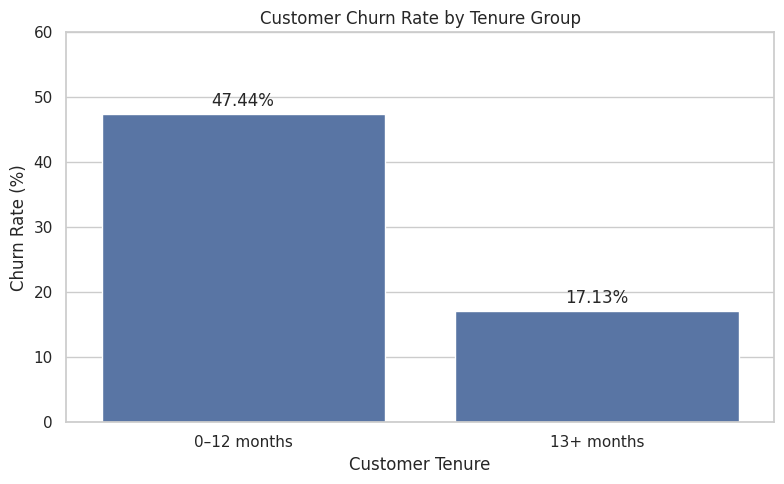

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=tenure_churn_rate,
    x="TenureGroup",
    y="ChurnRate"
)

# Add percentage labels
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.title("Customer Churn Rate by Tenure Group")
plt.xlabel("Customer Tenure")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 60)
plt.tight_layout()
plt.show()

In [25]:
contract_churn = (
    df.groupby("Contract")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .reset_index(name="ChurnRate")
)

contract_churn["ChurnRate"] = contract_churn["ChurnRate"].round(2)

print(contract_churn.sort_values("ChurnRate", ascending=False))

         Contract  ChurnRate
0  Month-to-month      42.71
1        One year      11.27
2        Two year       2.83


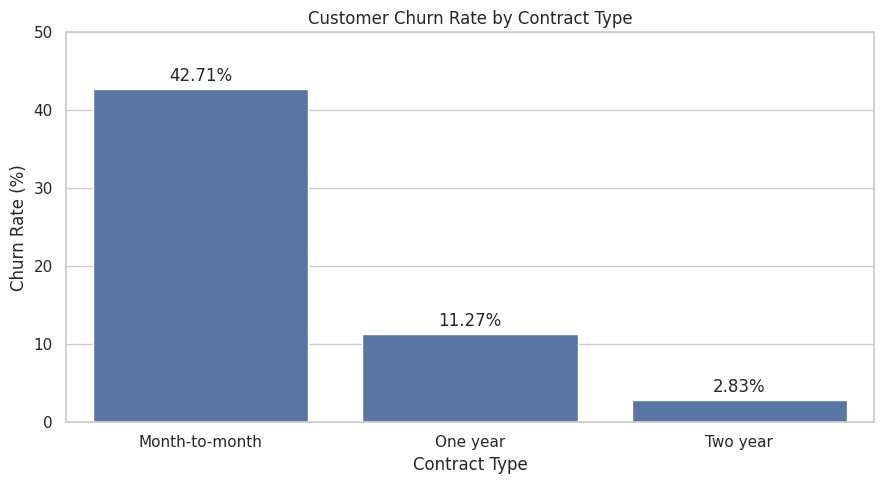

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns


contract_churn = (
    df.groupby("Contract")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .reset_index(name="ChurnRate")
)

contract_churn = contract_churn.sort_values(
    "ChurnRate", ascending=False
)

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=contract_churn,
    x="Contract",
    y="ChurnRate"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.title("Customer Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 50)
plt.tight_layout()
plt.show()

In [27]:
monthly_charges_analysis = (
    df.groupby("Churn")["MonthlyCharges"]
    .agg(["count", "mean", "median"])
    .round(2)
)

print(monthly_charges_analysis)

       count   mean  median
Churn                      
No      5174  61.27   64.43
Yes     1869  74.44   79.65


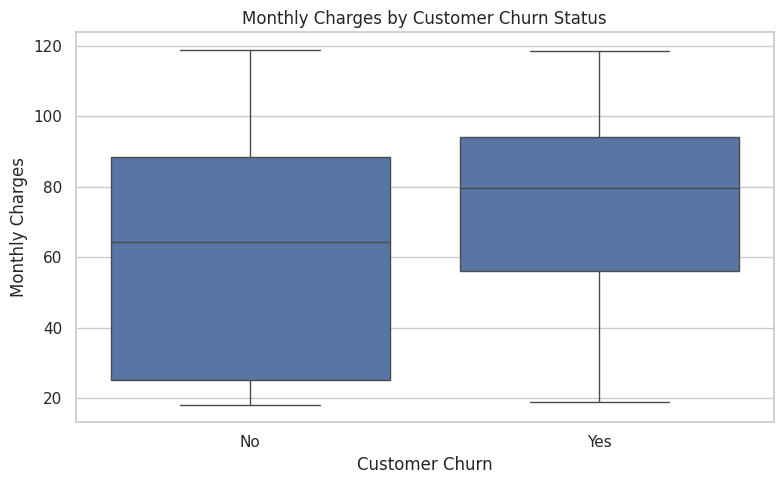

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges by Customer Churn Status")
plt.xlabel("Customer Churn")
plt.ylabel("Monthly Charges")
plt.tight_layout()
plt.show()

In [29]:
internet_churn = (
    df.groupby("InternetService")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .reset_index(name="ChurnRate")
)

internet_churn["ChurnRate"] = (
    internet_churn["ChurnRate"].round(2)
)

print(
    internet_churn.sort_values(
        "ChurnRate", ascending=False
    )
)

  InternetService  ChurnRate
1     Fiber optic      41.89
0             DSL      18.96
2              No       7.40


In [30]:
internet_churn = (
    df.groupby("InternetService")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .reset_index(name="ChurnRate")
)

internet_churn["ChurnRate"] = (
    internet_churn["ChurnRate"].round(2)
)

print(internet_churn.sort_values("ChurnRate", ascending=False))

  InternetService  ChurnRate
1     Fiber optic      41.89
0             DSL      18.96
2              No       7.40


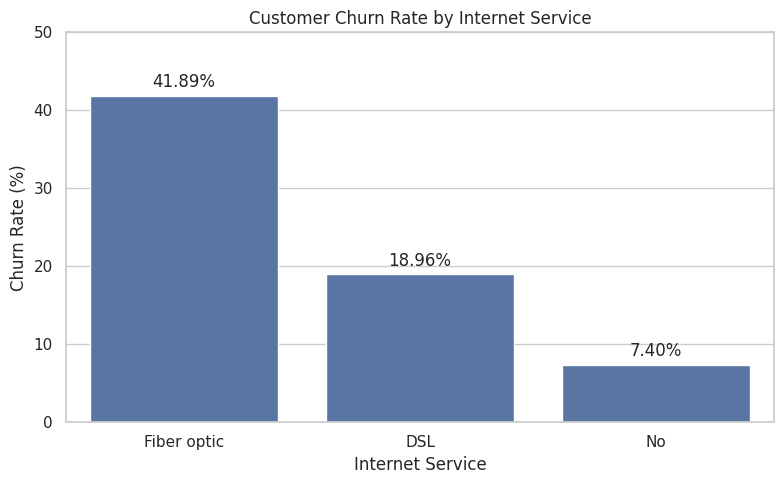

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

internet_churn = (
    df.groupby("InternetService")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .reset_index(name="ChurnRate")
    .sort_values("ChurnRate", ascending=False)
)

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=internet_churn,
    x="InternetService",
    y="ChurnRate"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.title("Customer Churn Rate by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 50)
plt.tight_layout()
plt.show()

In [32]:

service_contract = pd.crosstab(
    df["InternetService"],
    df["Contract"]
)

print(service_contract)

Contract         Month-to-month  One year  Two year
InternetService                                    
DSL                        1223       570       628
Fiber optic                2128       539       429
No                          524       364       638


In [33]:

service_contract_churn = (
    df.groupby(["InternetService", "Contract"])["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .reset_index(name="ChurnRate")
)

service_contract_churn["ChurnRate"] = (
    service_contract_churn["ChurnRate"].round(2)
)

print(service_contract_churn)

  InternetService        Contract  ChurnRate
0             DSL  Month-to-month      32.22
1             DSL        One year       9.30
2             DSL        Two year       1.91
3     Fiber optic  Month-to-month      54.61
4     Fiber optic        One year      19.29
5     Fiber optic        Two year       7.23
6              No  Month-to-month      18.89
7              No        One year       2.47
8              No        Two year       0.78


In [34]:

payment_churn = (
    df.groupby("PaymentMethod")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .reset_index(name="ChurnRate")
)

payment_churn["ChurnRate"] = (
    payment_churn["ChurnRate"].round(2)
)

print(
    payment_churn.sort_values(
        "ChurnRate", ascending=False
    )
)

               PaymentMethod  ChurnRate
2           Electronic check      45.29
3               Mailed check      19.11
0  Bank transfer (automatic)      16.71
1    Credit card (automatic)      15.24


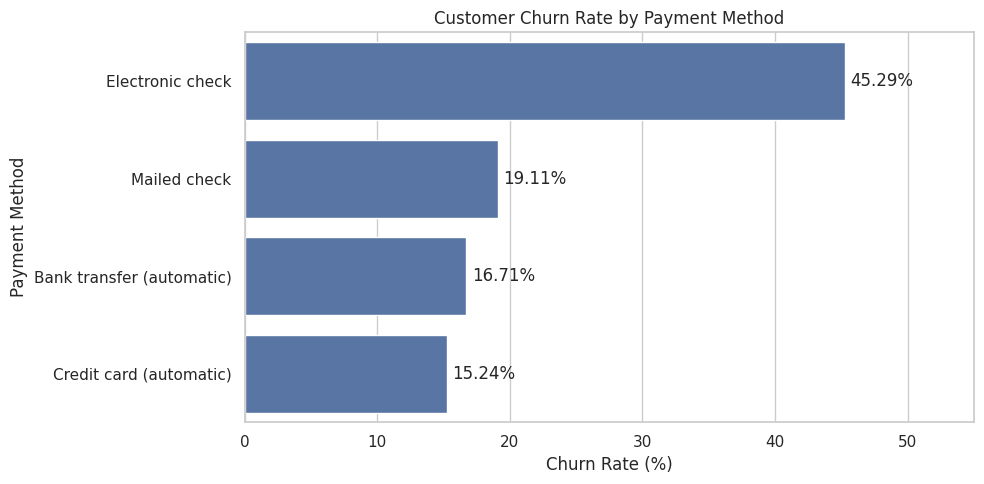

In [35]:
import matplotlib.pyplot as plt
import seaborn as sns

payment_churn = (
    df.groupby("PaymentMethod")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .reset_index(name="ChurnRate")
    .sort_values("ChurnRate", ascending=False)
)

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=payment_churn,
    x="ChurnRate",
    y="PaymentMethod"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=4)

plt.title("Customer Churn Rate by Payment Method")
plt.xlabel("Churn Rate (%)")
plt.ylabel("Payment Method")
plt.xlim(0, 55)
plt.tight_layout()
plt.show()


In [36]:


def calculate_churn_rate(column):
    return (
        df.groupby(column, observed=True)["Churn"]
        .apply(lambda x: (x == "Yes").mean() * 100)
        .round(2)
        .sort_values(ascending=False)
    )

print("CHURN RATE BY CONTRACT")
print(calculate_churn_rate("Contract"))

print("\nCHURN RATE BY INTERNET SERVICE")
print(calculate_churn_rate("InternetService"))

print("\nCHURN RATE BY PAYMENT METHOD")
print(calculate_churn_rate("PaymentMethod"))

print("\nCHURN RATE BY TENURE GROUP")
print(calculate_churn_rate("TenureGroup"))

CHURN RATE BY CONTRACT
Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn, dtype: float64

CHURN RATE BY INTERNET SERVICE
InternetService
Fiber optic    41.89
DSL            18.96
No              7.40
Name: Churn, dtype: float64

CHURN RATE BY PAYMENT METHOD
PaymentMethod
Electronic check             45.29
Mailed check                 19.11
Bank transfer (automatic)    16.71
Credit card (automatic)      15.24
Name: Churn, dtype: float64

CHURN RATE BY TENURE GROUP
TenureGroup
0–12 months    47.44
13+ months     17.13
Name: Churn, dtype: float64


In [37]:

import pandas as pd

X = df.drop(
    columns=["customerID", "Churn", "TenureGroup"],
    errors="ignore"
)


y = df["Churn"].map({"No": 0, "Yes": 1})

print("Feature dataset shape:", X.shape)
print("Target dataset shape:", y.shape)
print("\nTarget distribution:")
print(y.value_counts())

Feature dataset shape: (7043, 19)
Target dataset shape: (7043,)

Target distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [38]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression


numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])


categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])


model.fit(X_train, y_train)

print("Model training completed!")
print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Model training completed!
Training records: 5634
Testing records: 1409


In [39]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)
y_pred = model.predict(X_test)

y_prob = model.predict_proba(X_test)[:, 1]

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall:", round(recall_score(y_test, y_pred), 4))
print("F1-score:", round(f1_score(y_test, y_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))


Accuracy: 0.8055
Precision: 0.6572
Recall: 0.5588
F1-score: 0.604
ROC-AUC: 0.8421

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409

Confusion Matrix:
[[926 109]
 [165 209]]


In [40]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

# Predicted probabilities are already stored in y_prob
thresholds = [0.3, 0.4, 0.5]

results = []

for threshold in thresholds:
    y_pred_threshold = (y_prob >= threshold).astype(int)

    results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, y_pred_threshold),
        "Precision": precision_score(
            y_test, y_pred_threshold, zero_division=0
        ),
        "Recall": recall_score(y_test, y_pred_threshold),
        "F1-score": f1_score(y_test, y_pred_threshold)
    })

threshold_results = pd.DataFrame(results)

print(threshold_results.round(3))


   Threshold  Accuracy  Precision  Recall  F1-score
0        0.3     0.749      0.519   0.754     0.615
1        0.4     0.777      0.568   0.668     0.614
2        0.5     0.806      0.657   0.559     0.604


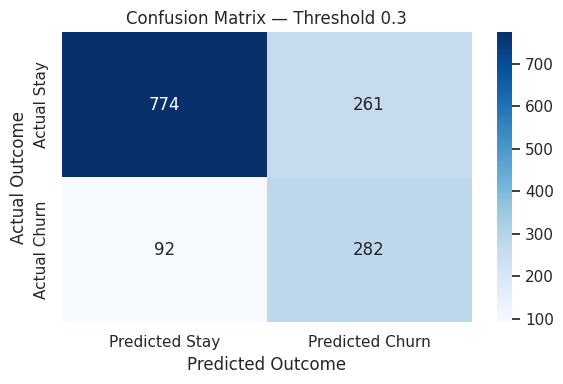

              precision    recall  f1-score   support

      Stayed       0.89      0.75      0.81      1035
     Churned       0.52      0.75      0.62       374

    accuracy                           0.75      1409
   macro avg       0.71      0.75      0.71      1409
weighted avg       0.79      0.75      0.76      1409



In [41]:

from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt


chosen_threshold = 0.3
y_pred_03 = (y_prob >= chosen_threshold).astype(int)


cm = confusion_matrix(y_test, y_pred_03)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted Stay", "Predicted Churn"],
    yticklabels=["Actual Stay", "Actual Churn"]
)

plt.title("Confusion Matrix — Threshold 0.3")
plt.xlabel("Predicted Outcome")
plt.ylabel("Actual Outcome")
plt.tight_layout()
plt.show()

print(classification_report(
    y_test,
    y_pred_03,
    target_names=["Stayed", "Churned"]
))


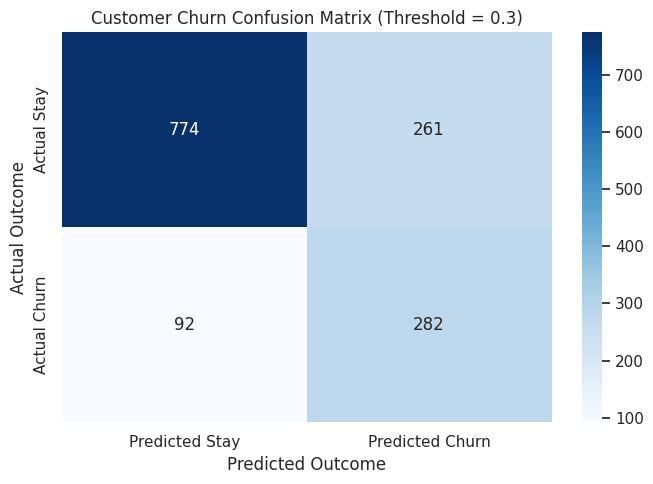

              precision    recall  f1-score   support

      Stayed       0.89      0.75      0.81      1035
     Churned       0.52      0.75      0.62       374

    accuracy                           0.75      1409
   macro avg       0.71      0.75      0.71      1409
weighted avg       0.79      0.75      0.76      1409



In [42]:

from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# Predict churn using threshold 0.3
chosen_threshold = 0.3
y_pred_03 = (y_prob >= chosen_threshold).astype(int)


cm = confusion_matrix(y_test, y_pred_03)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted Stay", "Predicted Churn"],
    yticklabels=["Actual Stay", "Actual Churn"]
)

plt.title("Customer Churn Confusion Matrix (Threshold = 0.3)")
plt.xlabel("Predicted Outcome")
plt.ylabel("Actual Outcome")
plt.tight_layout()
plt.show()


print(classification_report(
    y_test,
    y_pred_03,
    target_names=["Stayed", "Churned"]
))


In [43]:

preprocessor = model.named_steps["preprocessor"]
classifier = model.named_steps["classifier"]

feature_names = preprocessor.get_feature_names_out()
coefficients = classifier.coef_[0]


feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

feature_importance["Abs_Coefficient"] = (
    feature_importance["Coefficient"].abs()
)

feature_importance = feature_importance.sort_values(
    "Abs_Coefficient", ascending=False
)

print(feature_importance.head(15).round(3))


                                      Feature  Coefficient  Abs_Coefficient
1                                 num__tenure       -1.258            1.258
38                     cat__Contract_Two year       -0.777            0.777
15                   cat__InternetService_DSL       -0.649            0.649
16           cat__InternetService_Fiber optic        0.634            0.634
2                         num__MonthlyCharges       -0.592            0.592
36               cat__Contract_Month-to-month        0.583            0.583
3                           num__TotalCharges        0.536            0.536
39                   cat__PaperlessBilling_No       -0.343            0.343
25  cat__DeviceProtection_No internet service       -0.300            0.300
17                    cat__InternetService_No       -0.300            0.300
19    cat__OnlineSecurity_No internet service       -0.300            0.300
28       cat__TechSupport_No internet service       -0.300            0.300
31       cat

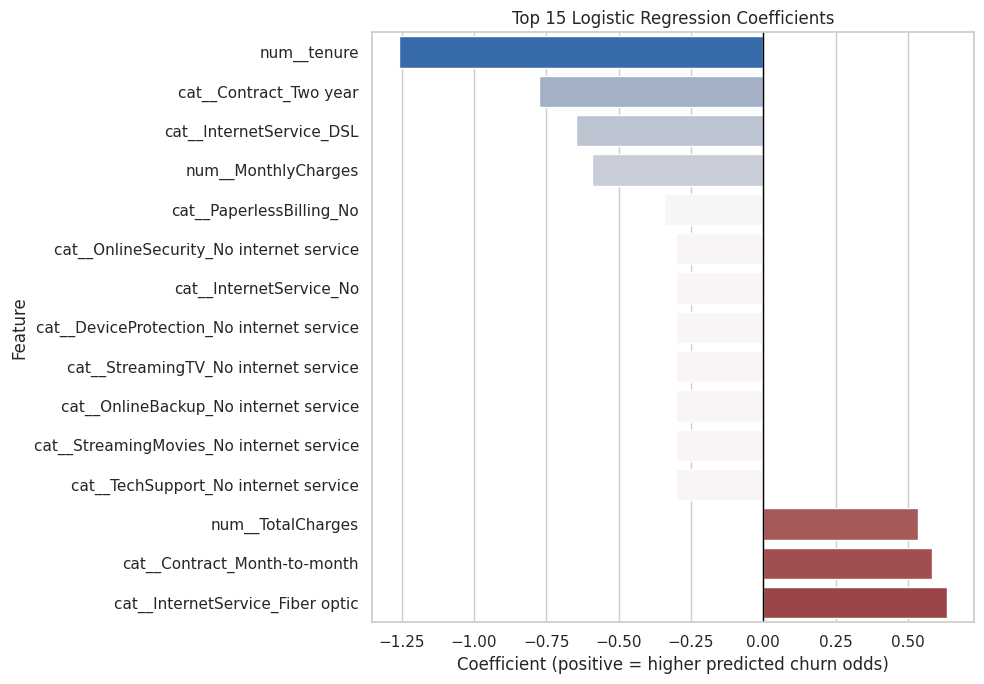

In [44]:


top_features = feature_importance.head(15).copy()


top_features = top_features.sort_values("Coefficient")

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x="Coefficient",
    y="Feature",
    hue="Coefficient",
    palette="vlag",
    legend=False
)

plt.axvline(0, color="black", linewidth=1)
plt.title("Top 15 Logistic Regression Coefficients")
plt.xlabel("Coefficient (positive = higher predicted churn odds)")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


In [45]:

df.to_csv("telco_churn_cleaned.csv", index=False)

print("CSV file created successfully!")


CSV file created successfully!


In [46]:

from google.colab import files

files.download("telco_churn_cleaned.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>